In [ ]:
# Sentiment Analysis using NLP and Machine Learning

## Objective
'''
To build machine learning models that classify text into
positive, negative, and neutral sentiments using Natural
Language Processing and TF-IDF feature extraction.
'''

'\nTo build machine learning models that classify text into\npositive, negative, and neutral sentiments using Natural\nLanguage Processing and TF-IDF feature extraction.\n'

In [ ]:
## Step 1: Inastall Required Libraries
!pip install wordcloud

In [ ]:
## step 2: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re

import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer



from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from wordcloud import WordCloud

In [ ]:
## Step 3: Download NLTK Resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [ ]:
## Step 4: Load Your Dataset
df = pd.read_csv('Amazon Product Reviews dataset.csv')

In [ ]:
## Step 5: Check Dataset
print("Dataset Shape:", df.shape)

Dataset Shape: (50, 18)


In [ ]:
print(df.head())

                            Uniq Id            Crawl Timestamp  \
0  10d8b81dc693db8a3f92e19254525d53  2020-03-17 02:32:10 +0000   
1  31ef1ee4961d3fcff33e363edd7677eb  2020-03-17 02:32:10 +0000   
2  6943e517922b051cbec496be32fbb57f  2020-03-17 02:32:10 +0000   
3  6778c794e6ac7112981d4ebb239d6826  2020-03-17 02:32:10 +0000   
4  2335a28ae24db3b2191080bfd98a86e0  2020-03-17 02:32:10 +0000   

                    Billing Uniq Id  Rating  \
0  c697dc43961526785292107b91a639e1     NaN   
1  c697dc43961526785292107b91a639e1     NaN   
2  c697dc43961526785292107b91a639e1     NaN   
3  c697dc43961526785292107b91a639e1     NaN   
4  c697dc43961526785292107b91a639e1     NaN   

                                        Review Title  Review Rating  \
0                           Best Natural Deodorant!!            5.0   
1          Schmidt's Charcoal Deodorant is the best!            5.0   
2                  Beware. Defective or counterfeit.            1.0   
3  Good for infrequent shavers in co

In [ ]:
print(df.columns)

Index(['Uniq Id', 'Crawl Timestamp', 'Billing Uniq Id', 'Rating',
       'Review Title', 'Review Rating', 'Review Date', 'User Id', 'Brand',
       'Category', 'Sub Category', 'Product Description', 'Asin', 'Url',
       'Review Content', 'Verified Purchase', 'Helpful Review Count',
       'Manufacturer Response'],
      dtype='object')


In [ ]:
print(df.dtypes)

Uniq Id                   object
Crawl Timestamp           object
Billing Uniq Id           object
Rating                   float64
Review Title              object
Review Rating            float64
Review Date               object
User Id                   object
Brand                     object
Category                  object
Sub Category              object
Product Description       object
Asin                      object
Url                       object
Review Content            object
Verified Purchase         object
Helpful Review Count      object
Manufacturer Response    float64
dtype: object


In [ ]:
print(df.isnull().sum())

Uniq Id                   0
Crawl Timestamp           0
Billing Uniq Id           0
Rating                   50
Review Title              0
Review Rating             0
Review Date               0
User Id                   0
Brand                     0
Category                  1
Sub Category              1
Product Description       1
Asin                      0
Url                       0
Review Content            0
Verified Purchase         0
Helpful Review Count      0
Manufacturer Response    50
dtype: int64


In [ ]:
## Step 6: Check review Rating
print(df['Review Rating'].value_counts(dropna=False))

Review Rating
5.0    34
1.0     6
4.0     5
3.0     3
2.0     2
Name: count, dtype: int64


In [ ]:
print(df['Rating'].value_counts(dropna=False))

Rating
NaN    50
Name: count, dtype: int64


In [ ]:
print(df[['Rating', 'Review Rating', 'Review Content']].head(10))

   Rating  Review Rating                                     Review Content
0     NaN            5.0  This is the one natural deodorant that works f...
1     NaN            5.0  I am staying away from the conventional deodor...
2     NaN            1.0  Do not buy this from Amazon it's either defect...
3     NaN            3.0  I started using this because I was getting cys...
4     NaN            1.0  Dont buy this from amazon!!!! I never write re...
5     NaN            5.0                 Great natural deodorant! It works!
6     NaN            5.0  Great for those who are sensitive to perfumed ...
7     NaN            2.0  Well I stopped using it today. Gave it about 3...
8     NaN            3.0  I was excited to try this deodorant. I have be...
9     NaN            5.0  The only deodorant I’ll ever use anymore, no o...


In [ ]:
## Step 7: Create a Sentiment Dataset
sentiment_df = df[['Review Content', 'Review Rating']].copy()

In [ ]:
sentiment_df.rename(
    columns={
        'Review Content': 'Review',
        'Review Rating': 'Rating'
    },
    inplace=True
)

In [ ]:
print(sentiment_df.head())

                                              Review  Rating
0  This is the one natural deodorant that works f...     5.0
1  I am staying away from the conventional deodor...     5.0
2  Do not buy this from Amazon it's either defect...     1.0
3  I started using this because I was getting cys...     3.0
4  Dont buy this from amazon!!!! I never write re...     1.0


In [ ]:
## Step 8: Convert Rating to Numeric
sentiment_df['Rating'] = pd.to_numeric(
    sentiment_df['Rating'],
    errors='coerce'
)

In [ ]:
print(sentiment_df['Rating'].value_counts(dropna=False))

Rating
5.0    34
1.0     6
4.0     5
3.0     3
2.0     2
Name: count, dtype: int64


In [ ]:
## Step 9: Remove Missing Reviews and Ratings
sentiment_df = sentiment_df.dropna(
    subset=['Review', 'Rating']
)

In [ ]:
sentiment_df = sentiment_df[
    sentiment_df['Review'].astype(str).str.strip() != ''
]

In [ ]:
print("Remaining records:", len(sentiment_df))

Remaining records: 50


In [ ]:
## Step 10: Create Sentiment Labels
def convert_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

In [ ]:
sentiment_df['Sentiment'] = sentiment_df['Rating'].apply(convert_sentiment)

In [ ]:
print(sentiment_df.head(10))

                                              Review  Rating Sentiment
0  This is the one natural deodorant that works f...     5.0  Positive
1  I am staying away from the conventional deodor...     5.0  Positive
2  Do not buy this from Amazon it's either defect...     1.0  Negative
3  I started using this because I was getting cys...     3.0   Neutral
4  Dont buy this from amazon!!!! I never write re...     1.0  Negative
5                 Great natural deodorant! It works!     5.0  Positive
6  Great for those who are sensitive to perfumed ...     5.0  Positive
7  Well I stopped using it today. Gave it about 3...     2.0  Negative
8  I was excited to try this deodorant. I have be...     3.0   Neutral
9  The only deodorant I’ll ever use anymore, no o...     5.0  Positive


In [ ]:
## Step 11:Check Sentiment Distribution

In [ ]:
print(sentiment_df['Sentiment'].value_counts())

Sentiment
Positive    39
Negative     8
Neutral      3
Name: count, dtype: int64


In [ ]:
print(
    sentiment_df['Sentiment'].value_counts(normalize=True) * 100
)

Sentiment
Positive    78.0
Negative    16.0
Neutral      6.0
Name: proportion, dtype: float64


In [ ]:
## Step 12: Visualize Sentiment Distribution

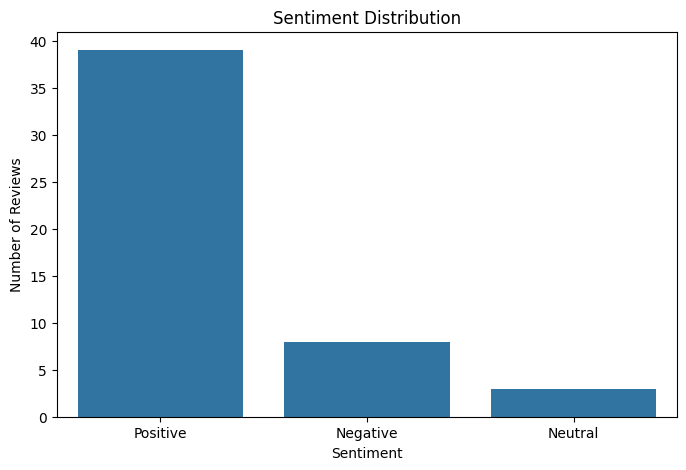

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=sentiment_df,
    x='Sentiment'
)

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

In [ ]:
## observation
'''
The dataset contains positive, negative, and neutral customer reviews. Positive reviews may be more frequent than negative and neutral reviews, indicating an imbalanced sentiment distribution.
'''

'\nThe dataset contains positive, negative, and neutral customer reviews. Positive reviews may be more frequent than negative and neutral reviews, indicating an imbalanced sentiment distribution.\n'

In [ ]:
## Step 13: Check Duplicate Reviews

In [ ]:
print(
    "Duplicate reviews:",
    sentiment_df['Review'].duplicated().sum()
)

Duplicate reviews: 0


In [ ]:
sentiment_df = sentiment_df.drop_duplicates(
    subset=['Review']
)

In [ ]:
print("Dataset shape after removing duplicates:", sentiment_df.shape)

Dataset shape after removing duplicates: (50, 3)


In [ ]:
## Step 14: Text preprocessing
   ## 1. Load Stopwords and Lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [ ]:
## Step 15: Create Preprocessing Function
def preprocess_text(text):

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # join words
    return ' '.join(tokens)

In [ ]:
## Step 16: Apply text preprocessing
sentiment_df['Clean_Review'] = sentiment_df['Review'].apply(
    preprocess_text
)
print(
    sentiment_df[['Review', 'Clean_Review']].head(10)
)


                                              Review  \
0  This is the one natural deodorant that works f...   
1  I am staying away from the conventional deodor...   
2  Do not buy this from Amazon it's either defect...   
3  I started using this because I was getting cys...   
4  Dont buy this from amazon!!!! I never write re...   
5                 Great natural deodorant! It works!   
6  Great for those who are sensitive to perfumed ...   
7  Well I stopped using it today. Gave it about 3...   
8  I was excited to try this deodorant. I have be...   
9  The only deodorant I’ll ever use anymore, no o...   

                                        Clean_Review  
0  one natural deodorant work bo smell throughout...  
1  staying away conventional deodorant lot fragra...  
2  buy amazon either defective counterfeit used b...  
3  started using getting cyst aluminum antiperspi...  
4  dont buy amazon never write review felt others...  
5                       great natural deodorant work 

In [ ]:
## step 17: Remove Empty Cleaned Reviews

In [ ]:
sentiment_df = sentiment_df[
    sentiment_df['Clean_Review'].str.strip() != ''
]
print(sentiment_df.shape)

(50, 4)


In [ ]:
## Step 18: WordCloud for Positive Reviews

In [ ]:
positive_text = ' '.join(
    sentiment_df[
        sentiment_df['Sentiment'] == 'Positive'
    ]['Clean_Review']
)

In [ ]:
wordcloud_positive = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

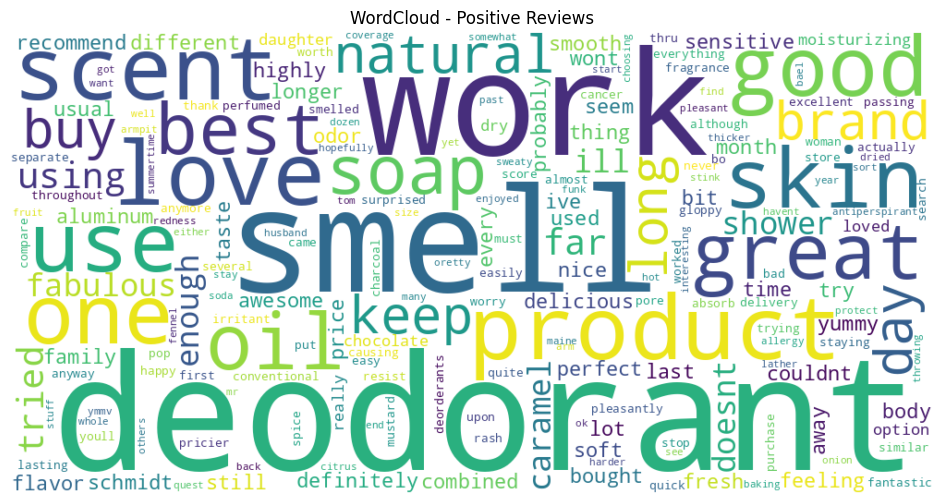

In [ ]:
plt.figure(figsize=(12, 6))

plt.imshow(
    wordcloud_positive,
    interpolation='bilinear'
)

plt.axis('off')

plt.title('WordCloud - Positive Reviews')

plt.show()

In [ ]:
## Step 19: WordCloud for Negative Reviews

In [ ]:
negative_text = ' '.join(
    sentiment_df[
        sentiment_df['Sentiment'] == 'Negative'
    ]['Clean_Review']
)

In [ ]:
wordcloud_negative = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

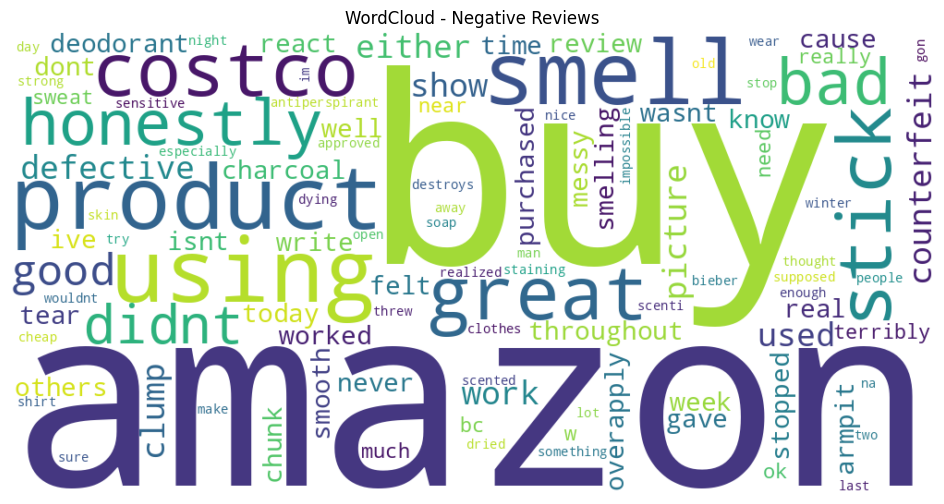

In [ ]:
plt.figure(figsize=(12, 6))

plt.imshow(
    wordcloud_negative,
    interpolation='bilinear'
)

plt.axis('off')

plt.title('WordCloud - Negative Reviews')

plt.show()

In [ ]:
## Step 20: WordCloud for Neutral Reviews

In [ ]:
neutral_text = ' '.join(
    sentiment_df[
        sentiment_df['Sentiment'] == 'Neutral'
    ]['Clean_Review']
)

In [ ]:
print(
    "Number of neutral reviews:",
    len(
        sentiment_df[
            sentiment_df['Sentiment'] == 'Neutral'
        ]
    )
)

Number of neutral reviews: 3


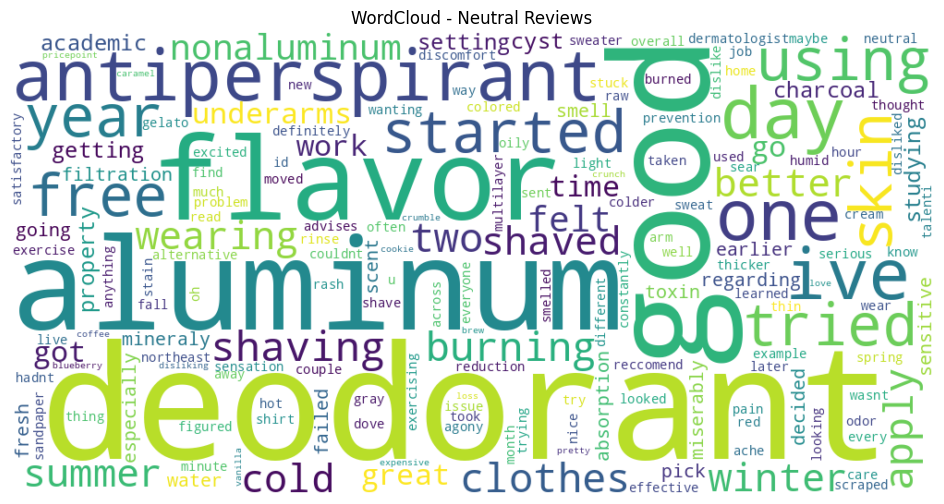

In [ ]:
if len(neutral_text.strip()) > 0:

    wordcloud_neutral = WordCloud(
        width=1000,
        height=500,
        background_color='white'
    ).generate(neutral_text)

    plt.figure(figsize=(12, 6))

    plt.imshow(
        wordcloud_neutral,
        interpolation='bilinear'
    )

    plt.axis('off')

    plt.title('WordCloud - Neutral Reviews')

    plt.show()

In [ ]:
## Step 21: prepare X and Y

In [ ]:
X = sentiment_df['Clean_Review']

y = sentiment_df['Sentiment']

In [ ]:
print(X.head())
print(y.head())

0    one natural deodorant work bo smell throughout...
1    staying away conventional deodorant lot fragra...
2    buy amazon either defective counterfeit used b...
3    started using getting cyst aluminum antiperspi...
4    dont buy amazon never write review felt others...
Name: Clean_Review, dtype: object
0    Positive
1    Positive
2    Negative
3     Neutral
4    Negative
Name: Sentiment, dtype: object


In [ ]:
## Step 22: Train-Test Split - 80/20

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40
Testing samples: 10


In [ ]:
## Step 23: TF_IDF Vectorization

In [ ]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

In [ ]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [ ]:
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (40, 1108)
Testing TF-IDF shape: (10, 1108)


In [ ]:
tfidf.fit_transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1351 stored elements and shape (40, 1108)>

In [ ]:
## Step 24: Model 1  Naive Baves

In [ ]:
nb_model = MultinomialNB()

In [ ]:
nb_model.fit(
    X_train_tfidf,
    y_train
)

MultinomialNB()

In [ ]:
y_pred_nb = nb_model.predict(
    X_test_tfidf
)

In [ ]:
## step 25: Evaluate Navie Bayes

In [ ]:
nb_accuracy = accuracy_score(
    y_test,
    y_pred_nb
)

print("Naive Bayes Accuracy:", nb_accuracy)

Naive Bayes Accuracy: 0.8


In [ ]:
nb_precision = precision_score(
    y_test,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

print("Naive Bayes Precision:", nb_precision)

Naive Bayes Precision: 0.64


In [ ]:
nb_recall = recall_score(
    y_test,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

print("Naive Bayes Recall:", nb_recall)

Naive Bayes Recall: 0.8


In [ ]:
nb_f1 = f1_score(
    y_test,
    y_pred_nb,
    average='weighted',
    zero_division=0
)

print("Naive Bayes F1 Score:", nb_f1)

Naive Bayes F1 Score: 0.711111111111111


In [ ]:
## Step 26: Classification Reprt - Naive Bayes

In [ ]:
print(
    classification_report(
        y_test,
        y_pred_nb,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
     Neutral       0.00      0.00      0.00         1
    Positive       0.80      1.00      0.89         8

    accuracy                           0.80        10
   macro avg       0.27      0.33      0.30        10
weighted avg       0.64      0.80      0.71        10



In [ ]:
## Step 27: Confusion Matrix - Naive Bayes

In [ ]:
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=['Negative', 'Neutral', 'Positive']
)

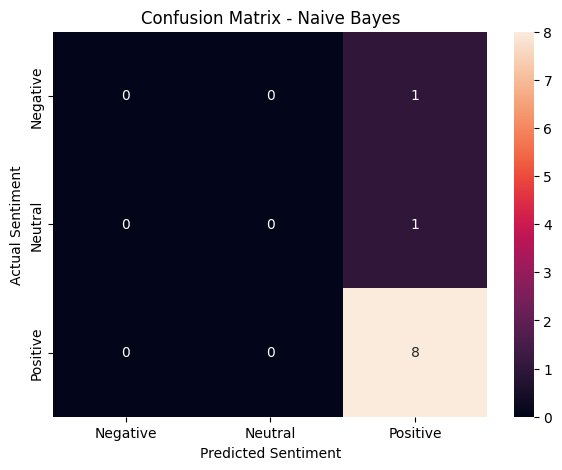

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('Confusion Matrix - Naive Bayes')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [ ]:
## Step 28: Model 2 - Linear SVM

In [ ]:
svm_model = LinearSVC(
    random_state=42
)

In [ ]:
svm_model.fit(
    X_train_tfidf,
    y_train
)

LinearSVC(random_state=42)

In [ ]:
y_pred_svm = svm_model.predict(
    X_test_tfidf
)

In [ ]:
## Step 29: Evaluate SVM

In [ ]:
svm_accuracy = accuracy_score(
    y_test,
    y_pred_svm
)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.8


In [ ]:
svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

print("SVM Precision:", svm_precision)

SVM Precision: 0.64


In [ ]:
svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

print("SVM Recall:", svm_recall)

SVM Recall: 0.8


In [ ]:
svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    average='weighted',
    zero_division=0
)

print("SVM F1 Score:", svm_f1)

SVM F1 Score: 0.711111111111111


In [ ]:
## Step 30: Classification Report - SVM

In [ ]:
print(
    classification_report(
        y_test,
        y_pred_svm,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
     Neutral       0.00      0.00      0.00         1
    Positive       0.80      1.00      0.89         8

    accuracy                           0.80        10
   macro avg       0.27      0.33      0.30        10
weighted avg       0.64      0.80      0.71        10



In [ ]:
## Step 31: Confusion Matrix - SVM

In [ ]:
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=['Negative', 'Neutral', 'Positive']
)

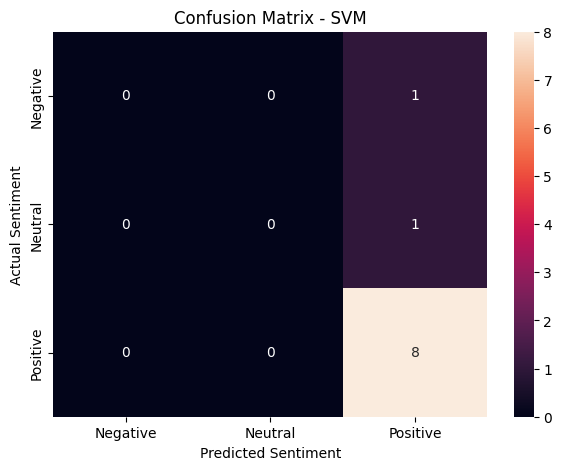

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('Confusion Matrix - SVM')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [ ]:
## Step 32: Comapare Both Models

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Naive Bayes',
        'Linear SVM'
    ],
    'Accuracy': [
        nb_accuracy,
        svm_accuracy
    ],
    'Precision': [
        nb_precision,
        svm_precision
    ],
    'Recall': [
        nb_recall,
        svm_recall
    ],
    'F1 Score': [
        nb_f1,
        svm_f1
    ]
})

print(results)

         Model  Accuracy  Precision  Recall  F1 Score
0  Naive Bayes       0.8       0.64     0.8  0.711111
1   Linear SVM       0.8       0.64     0.8  0.711111


In [ ]:
## Step 33: Visualize Model Performance

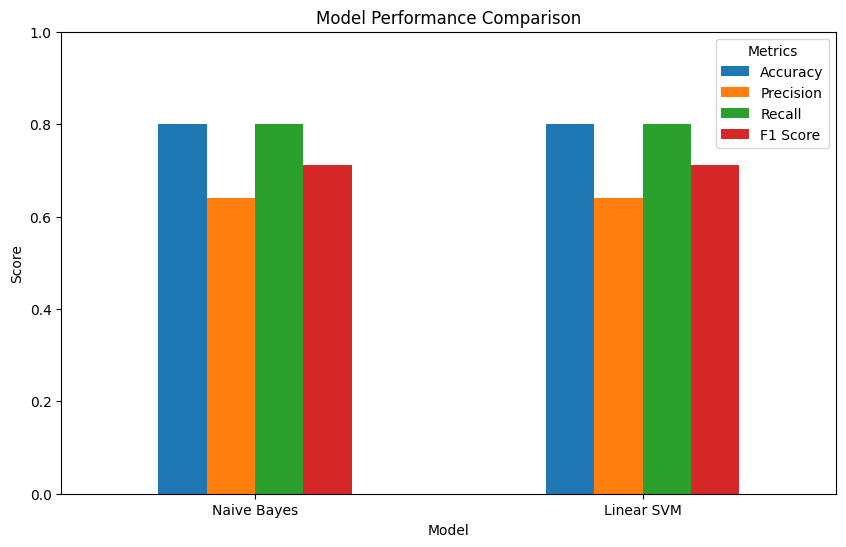

In [ ]:
results_plot = results.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(
    title='Metrics'
)

plt.show()

In [ ]:
## Observation
'''
Compare:

Accuracy
Precision
Recall
F1 Score

The model with the highest overall F1 score can generally be considered the better-performing model, especially when classes are imbalanced.
'''

'\nCompare:\n\nAccuracy\nPrecision\nRecall\nF1 Score\n\nThe model with the highest overall F1 score can generally be considered the better-performing model, especially when classes are imbalanced.\n'

In [ ]:
## Step 34: Identify the best model
best_model = results.loc[
    results['F1 Score'].idxmax()
]

print("Best Model:")
print(best_model)

Best Model:
Model        Naive Bayes
Accuracy             0.8
Precision           0.64
Recall               0.8
F1 Score        0.711111
Name: 0, dtype: object


In [ ]:
## step 35: Error Analysis

In [ ]:
error_df = pd.DataFrame({
    'Review': X_test.values,
    'Actual Sentiment': y_test.values,
    'Predicted Sentiment': y_pred_svm
})

In [ ]:
errors = error_df[
    error_df['Actual Sentiment'] !=
    error_df['Predicted Sentiment']
]

In [ ]:
print("Number of misclassified reviews:", len(errors))

Number of misclassified reviews: 2


In [ ]:
## Step 36: Display 5 Misclassified Reviews

In [ ]:
print(
    errors.head(5).to_string(index=False)
)

                                                                                                                                                                                                                                                          Review Actual Sentiment Predicted Sentiment
                                                                                                                                                                                                                                                  dried skin lot         Negative            Positive
one thing ive learned trying different flavor talenti gelato one flavor everyone disliked flavor tried dislike multilayer flavor pricepoint disliking one great loss love vanilla blueberry crumble expensive caramel cookie crunch cold coffee brew pretty good          Neutral            Positive


In [ ]:
for i, row in errors.head(5).iterrows():

    print("Review:", row['Review'])
    print("Actual:", row['Actual Sentiment'])
    print("Predicted:", row['Predicted Sentiment'])
    print("-" * 80)

Review: dried skin lot
Actual: Negative
Predicted: Positive
--------------------------------------------------------------------------------
Review: one thing ive learned trying different flavor talenti gelato one flavor everyone disliked flavor tried dislike multilayer flavor pricepoint disliking one great loss love vanilla blueberry crumble expensive caramel cookie crunch cold coffee brew pretty good
Actual: Neutral
Predicted: Positive
--------------------------------------------------------------------------------


In [ ]:
## Step 37: Final Dataset Check

In [ ]:
print(sentiment_df.head())

                                              Review  Rating Sentiment  \
0  This is the one natural deodorant that works f...     5.0  Positive   
1  I am staying away from the conventional deodor...     5.0  Positive   
2  Do not buy this from Amazon it's either defect...     1.0  Negative   
3  I started using this because I was getting cys...     3.0   Neutral   
4  Dont buy this from amazon!!!! I never write re...     1.0  Negative   

                                        Clean_Review  
0  one natural deodorant work bo smell throughout...  
1  staying away conventional deodorant lot fragra...  
2  buy amazon either defective counterfeit used b...  
3  started using getting cyst aluminum antiperspi...  
4  dont buy amazon never write review felt others...  


In [ ]:
## Step 38: Save Processed Dataset

In [ ]:
sentiment_df.to_csv(
    '/content/sentiment_processed.csv',
    index=False
)
print("Processed dataset saved successfully.")

Processed dataset saved successfully.


In [ ]:
# Conclusion
'''
Sentiment analysis was performed on customer reviews using text preprocessing and TF-IDF feature extraction. Naive Bayes and SVM classifiers were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices. The analysis helps identify customer opinions and can support businesses in improving products, services, and customer satisfaction.
'''

'\nSentiment analysis was performed on customer reviews using text preprocessing and TF-IDF feature extraction. Naive Bayes and SVM classifiers were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices. The analysis helps identify customer opinions and can support businesses in improving products, services, and customer satisfaction.\n'